# [drosophila_body_orientation_predictor](https://github.com/nehalsinghmangat/drosophila_body_orientation_predictor) — ANN Performance Examples

The single example in `02_training_and_testing_the_ann.ipynb` (`figures/ann_performance_example`), extended to several held-out trajectories: one row per trajectory, each shown three ways (ground-truth heading, the Möbius regression on airspeed direction, the ANN).

1. **Candidates.** Every held-out trajectory is scored on length, turning and self-intersection; a pool of candidates covering all three wind speeds and a range of groundspeeds is drawn from it, and plotted.
2. **Selection.** The trajectories listed in `SELECTED` are plotted and saved as `figures/ann_performance_examples.{pdf,png}`.

Run after `02_training_and_testing_the_ann.ipynb` (it needs `../models/ann_model.keras`). It uses the same trajectory-grouped split (seed 42, 33% test) and the same Möbius fit as that notebook. Error is the median per-trajectory angular error (deg).

## Setup

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import keras
from scipy.optimize import minimize
from sklearn.model_selection import GroupShuffleSplit

sys.path.insert(0, os.path.abspath('../utils'))
import fly_plot_lib_plot as fpl
from utils import circular_distance, pull_out_individual_trajectories, augment_trajectories, register_geodesic_loss

RANDOM_SEED = 42
os.makedirs('../figures', exist_ok=True)

data = pd.read_csv('../trainingdata/04_trainingdata/all_wind_heading_and_trajectories_augmented_corrected_filtered_headx_heady.csv')

# same trajectory-grouped split as 02_training_and_testing_the_ann.ipynb (seed 42, 33% test)
traj_ids = data['trajec_objid'].unique()
gss = GroupShuffleSplit(n_splits=1, test_size=0.33, random_state=RANDOM_SEED)
train_idx, test_idx = next(gss.split(np.zeros((len(traj_ids), 1)), groups=traj_ids))
train_ids = set(traj_ids[train_idx])
test_ids = set(traj_ids[test_idx])
train_df = data[data['trajec_objid'].isin(train_ids)].reset_index(drop=True)

trajs = pull_out_individual_trajectories(data, min_traj_length=12)
# a handful of trajec_objid values label two recorded sub-segments; leave those out
n_segments = pd.Series([t['trajec_objid'].iloc[0] for t in trajs]).value_counts()
test_trajs = {t['trajec_objid'].iloc[0]: t.reset_index(drop=True) for t in trajs
              if t['trajec_objid'].iloc[0] in test_ids and n_segments[t['trajec_objid'].iloc[0]] == 1}
print(len(test_trajs), 'held-out trajectories')

INPUTS = ['groundspeed', 'groundspeed_angle', 'airspeed', 'airspeed_angle']
KEEP = ['heading_angle_x', 'heading_angle_y', 'trajec_objid']
register_geodesic_loss()
ann = keras.models.load_model('../models/ann_model.keras')

def ann_heading(traj):
    """ANN heading for every frame of one trajectory (first frame repeated, as in 02_training_and_testing_the_ann.ipynb)"""
    emb = augment_trajectories([traj], input_names=INPUTS, output_names=KEEP)
    p = ann(emb.iloc[:, :len(INPUTS)].values.astype('float32'), training=False).numpy()   # ann.predict can deadlock when called many times
    h = np.arctan2(p[:, 1], p[:, 0])
    return np.concatenate([np.full(len(traj) - len(h), h[0]), h])

Detected 3425 trajectories.
3343 trajectories with more than 12 timesteps.
1096 held-out trajectories


## Möbius baseline (airspeed direction)

$\hat\theta = \mu + 2\arctan(\beta\tan\frac{\theta_{air}-\nu}{2})$, fit on the training trajectories by minimising $\sum(1-\cos e)$, as in `02_training_and_testing_the_ann.ipynb`.

In [2]:
def circ_mean(a): return np.arctan2(np.sin(a).mean(), np.cos(a).mean())
def mobius(x, mu, nu, lb): return mu + 2 * np.arctan(np.exp(lb) * np.tan((x - nu) / 2))

def fit_mobius(x, y):
    best = None
    for nu0 in np.linspace(0, 2 * np.pi, 8, endpoint=False):
        for lb0 in (-1.0, 0.0, 1.0, 2.0):
            r = minimize(lambda p: np.mean(1 - np.cos(y - mobius(x, *p))), [circ_mean(y - x), nu0, lb0],
                         method='Nelder-Mead', options=dict(xatol=1e-6, fatol=1e-10, maxiter=4000))
            if best is None or r.fun < best.fun: best = r
    return best.x

params = fit_mobius(train_df['airspeed_angle'].values, train_df['heading_angle'].values)
print(f'mu={params[0]:.3f}  nu={params[1]:.3f}  beta={np.exp(params[2]):.2f}')

mu=0.034  nu=0.025  beta=0.59


## Scoring every held-out trajectory

Per trajectory, in the horizontal (x, y) plane the figure shows:

- `path_len`: distance travelled (m), the summed frame-to-frame step length.
- `n_crossings`: number of times the path crosses itself (pairs of non-adjacent segments that intersect).
- `heading_range`, `course_range`: range of the unwrapped body heading and of the unwrapped groundspeed direction (deg), i.e. how much the fly turns.
- `mean_groundspeed`, `upwind_frac` (fraction of frames with heading within 45° of upwind, −x), and the ANN and Möbius errors.

In [3]:
def n_self_crossings(x, y):
    """number of pairs of non-adjacent path segments that intersect"""
    a = np.column_stack([x, y])[:-1]; d = np.diff(np.column_stack([x, y]), axis=0)
    def cross(u, v): return u[..., 0] * v[..., 1] - u[..., 1] * v[..., 0]
    den = cross(d[:, None], d[None, :])
    with np.errstate(divide='ignore', invalid='ignore'):
        s = cross(a[None, :] - a[:, None], d[None, :]) / den
        u = cross(a[None, :] - a[:, None], d[:, None]) / den
    hit = (den != 0) & (s > 0) & (s < 1) & (u > 0) & (u < 1)
    i, j = np.triu_indices(len(a), k=2)
    return int(hit[i, j].sum())

rows, preds = [], {}
for tid, t in test_trajs.items():
    x, y, truth = t['position_x'].values, t['position_y'].values, t['heading_angle'].values
    h_ann = ann_heading(t)
    h_mob = mobius(t['airspeed_angle'].values, *params)
    preds[tid] = (h_mob, h_ann)
    rows.append({'trajec_objid': tid, 'windspeed': t['windspeed'].iloc[0], 'n_frames': len(t),
                 'path_len': np.hypot(np.diff(x), np.diff(y)).sum(), 'n_crossings': n_self_crossings(x, y),
                 'heading_range': np.degrees(np.ptp(np.unwrap(truth))),
                 'course_range': np.degrees(np.ptp(np.unwrap(t['groundspeed_angle'].values))),
                 'mean_groundspeed': t['groundspeed'].mean(),
                 'upwind_frac': np.mean(np.abs(np.abs(np.degrees(truth)) - 180) <= 45),
                 'ann_err': np.median(np.degrees(circular_distance(truth, h_ann))),
                 'mobius_err': np.median(np.degrees(circular_distance(truth, h_mob)))})
res = pd.DataFrame(rows).set_index('trajec_objid')
res[['n_frames', 'path_len', 'n_crossings', 'heading_range', 'course_range', 'mean_groundspeed', 'ann_err', 'mobius_err']].describe().round(3)

,n_frames,path_len,n_crossings,heading_range,course_range,mean_groundspeed,ann_err,mobius_err
count,1096.000,1096.000,1096.000,1096.000,1096.000,1096.000,1096.000,1096.000
mean,34.031,0.093,0.111,73.176,82.728,0.349,19.221,21.051
std,35.013,0.062,0.589,79.673,107.113,0.172,35.481,31.218
min,13.000,0.001,0.000,1.932,0.555,0.004,0.362,0.652
25%,18.750,0.064,0.000,24.241,21.373,0.222,2.897,4.440
50%,25.000,0.094,0.000,53.087,46.326,0.328,5.429,7.903
75%,37.000,0.112,0.000,92.735,103.142,0.463,14.202,20.645
max,686.000,1.276,9.000,747.214,1048.329,0.967,179.062,177.003


## Candidates

A candidate does not cross itself, is in the longest quarter of held-out trajectories by distance travelled, and turns (body heading range ≥ 60° and course range ≥ 45°). Near-hovering flight (mean groundspeed < 0.1 m/s), whose course direction is noisy, is left out, and so are ANN failures (median error > 30°; these are covered by `figures/ann_performance_errors`), several of which have both the ANN and Möbius predictions about 180° off, i.e. a likely heading-correction error in the ground truth.

To cover the range of trajectories, the candidates are grouped by wind speed (0.3, 0.4, 0.6 m/s) and by mean groundspeed (slow < 0.25 m/s ≤ medium < 0.4 m/s ≤ fast), and the `PER_GROUP` longest of each of the nine groups are kept. The example from `02_training_and_testing_the_ann.ipynb` is added as the first row.

In [4]:
PAPER_EXAMPLE = '20130327_193200_8714'   # figures/ann_performance_example
MIN_HEADING_RANGE, MIN_COURSE_RANGE = 60, 45   # deg
MIN_GROUNDSPEED = 0.1                          # m/s
MAX_ANN_ERR = 30                               # deg
GROUNDSPEED_BINS = [MIN_GROUNDSPEED, 0.25, 0.4, np.inf]
PER_GROUP = 2

pool = res[(res['n_crossings'] == 0) & (res['path_len'] >= res['path_len'].quantile(0.75))
           & (res['heading_range'] >= MIN_HEADING_RANGE) & (res['course_range'] >= MIN_COURSE_RANGE)
           & (res['mean_groundspeed'] >= MIN_GROUNDSPEED) & (res['ann_err'] <= MAX_ANN_ERR)].copy()
pool['speed'] = pd.cut(pool['mean_groundspeed'], GROUNDSPEED_BINS, labels=['slow', 'medium', 'fast'], right=False)
print(len(pool), 'trajectories meet the criteria')
display(pd.crosstab(pool['windspeed'], pool['speed']))

picked = (pool.sort_values('path_len', ascending=False)
              .groupby(['windspeed', 'speed'], observed=True).head(PER_GROUP)
              .sort_values(['windspeed', 'speed', 'path_len'], ascending=[True, True, False]))
candidates = [PAPER_EXAMPLE] + [tid for tid in picked.index if tid != PAPER_EXAMPLE]
cand_table = res.loc[candidates].join(pool['speed'])
cand_table.index = pd.Index(candidates, name='trajec_objid')
cand_table.insert(0, 'row', range(1, len(candidates) + 1))
cand_table.round(3)

95 trajectories meet the criteria


speed,slow,medium,fast
windspeed,,,
0.3,13,20,9
0.4,14,9,6
0.6,9,11,4


,row,windspeed,n_frames,path_len,n_crossings,heading_range,course_range,mean_groundspeed,upwind_frac,ann_err,mobius_err,speed
trajec_objid,,,,,,,,,,,,
20130327_193200_8714,1,0.3,40,0.137,0,97.788,81.423,0.352,0.000,4.328,26.887,medium
20130401_180544_13733,2,0.3,96,0.184,0,201.136,323.262,0.195,0.562,12.777,20.618,slow
20130327_193200_10295,3,0.3,81,0.157,0,163.692,190.295,0.196,0.506,7.478,8.351,slow
20130401_180544_10224,4,0.3,80,0.197,0,168.006,198.499,0.251,0.538,6.195,8.364,medium
20130401_180544_14669,5,0.3,64,0.176,0,117.020,138.685,0.280,0.641,4.872,7.455,medium
20130401_180544_14554,6,0.3,58,0.235,0,174.373,156.236,0.412,0.776,19.197,22.190,fast
20130328_180731_12240,7,0.3,32,0.138,0,89.904,67.282,0.443,0.000,2.958,2.407,fast
20121210_201202_4248,8,0.4,108,0.228,0,165.162,240.489,0.213,0.685,12.888,17.282,slow
20130321_182151_5431,9,0.4,71,0.160,0,77.579,119.166,0.230,0.958,3.897,4.390,slow


## Plotting

Same layout as `figures/ann_performance_example`: ground truth (black), Möbius (red) and ANN (blue), each prediction drawn over a faint ground truth; wedges go from a lighter tint at the start of the trajectory to the full color at the end, to show the direction of motion, with the three panels of a row on the same axis limits. The first panel's title gives the wind speed, mean groundspeed, frame count and distance travelled.

In [5]:
BLUE, RED, GREY = '#2166ac', '#b2182b', '#666666'

def draw_heading(ax, x, y, h, color, alpha, radius, every, fade=True):
    """heading wedges; with fade, they go from a lighter tint of color (first frame) to color (last frame)"""
    rgb = np.array(mcolors.to_rgb(color))
    start = 0.5 * rgb + 0.5 if fade else rgb   # halfway to white: black -> medium grey
    cmap = mcolors.LinearSegmentedColormap.from_list('_c', [start, rgb])
    fpl.colorline_with_heading(ax, np.flip(x[::every]), np.flip(y[::every]), np.flip(np.linspace(0, 1, len(x[::every]))),
                               np.flip(h[::every]), nskip=0, size_radius=radius, deg=False, colormap=cmap,
                               center_point_size=0.0001, colornorm=[0, 1], show_centers=False,
                               size_angle=20, alpha=alpha, edgecolor='none')

def plot_examples(tids, panel_width=5.0, min_aspect=0.3, numbered=False):
    """one row per trajectory: ground truth, Mobius and ANN heading"""
    limits = []
    for tid in tids:
        t = test_trajs[tid]
        x, y = t['position_x'].values, t['position_y'].values
        pad = 0.08 * max(np.ptp(x), np.ptp(y))
        limits.append(((x.min() - pad, x.max() + pad), (y.min() - pad, y.max() + pad)))
    aspects = [max(np.ptp(yl) / np.ptp(xl), min_aspect) for xl, yl in limits]

    height = sum(panel_width * a + 1.0 for a in aspects)
    fig = plt.figure(figsize=(3 * panel_width + 1, height), dpi=150)
    gs = fig.add_gridspec(len(tids), 3, height_ratios=aspects, hspace=0.55, wspace=0.12,
                          top=1 - 0.6 / height, bottom=0.5 / height)   # margins in inches
    for i, tid in enumerate(tids):
        t, r = test_trajs[tid], res.loc[tid]
        x, y, truth = t['position_x'].values, t['position_y'].values, t['heading_angle'].values
        h_mob, h_ann = preds[tid]
        extent = max(np.ptp(x), np.ptp(y)); radius = 0.045 * extent
        every = max(2, len(t) // 28)
        label = f'{i + 1}. {tid}' if numbered else tid
        panels = [(f'{label}: ground truth heading\n{r["windspeed"]:.1f} m/s wind, {r["mean_groundspeed"]:.2f} m/s ground, '
                   f'{int(r["n_frames"])} frames, {r["path_len"]:.2f} m', None, GREY),
                  (f'Möbius regression on airspeed direction\nmedian error {r["mobius_err"]:.1f}°', h_mob, RED),
                  (f'ANN\nmedian error {r["ann_err"]:.1f}°', h_ann, BLUE)]
        for j, (title, h, color) in enumerate(panels):
            ax = fig.add_subplot(gs[i, j])
            if j == 0: ax0 = ax
            ax.plot(x, y, color='0.7', lw=1, zorder=1)
            if h is None:
                draw_heading(ax, x, y, truth, 'black', 0.85, radius, every)
            else:
                draw_heading(ax, x, y, truth, 'black', 0.25, radius, every, fade=False)   # faint ground truth underneath
                draw_heading(ax, x, y, h, color, 0.75, radius, every)
            ax.set_xlim(*limits[i][0]); ax.set_ylim(*limits[i][1])
            ax.set_aspect('equal', adjustable='datalim')
            ax.set_title(title, fontsize=10, loc='left' if j == 0 else 'center')
            if j > 0: ax.tick_params(labelleft=False)
            if i == len(tids) - 1: ax.set_xlabel('x (m)')
        ax0.set_ylabel('y (m)')
    return fig

### All candidates

Pick the rows to keep for `SELECTED` below by their number. Panel titles give the median per-trajectory error.



In [6]:
fig = plot_examples(candidates, numbered=True)
plt.show()

## Selected examples

The trajectories for the figure. Provisional pick, candidate rows 1, 3, 11, 12, 14 and 19: two per wind speed, mean groundspeed from 0.20 to 0.60 m/s, mostly-upwind and mostly-downwind flight, and three trajectories (1, 11, 19) on which the Möbius baseline fails and the ANN does not. Saved as `figures/ann_performance_examples.{pdf,png}`.

     windspeed  n_frames  path_len  n_crossings  heading_range  course_range  mean_groundspeed  upwind_frac  ann_err  mobius_err   speed
row                                                                                                                                     
1          0.3        40      0.14            0          97.79         81.42              0.35         0.00     4.33       26.89  medium
3          0.3        81      0.16            0         163.69        190.29              0.20         0.51     7.48        8.35    slow
11         0.4        54      0.16            0         155.43        120.84              0.31         0.04     7.61       28.02  medium
12         0.4        22      0.13            0          66.92         64.05              0.60         0.68     1.61        2.86    fast
14         0.6       111      0.22            0         124.55        188.90              0.20         0.80     7.52       11.93    slow
19         0.6        25      0.13       

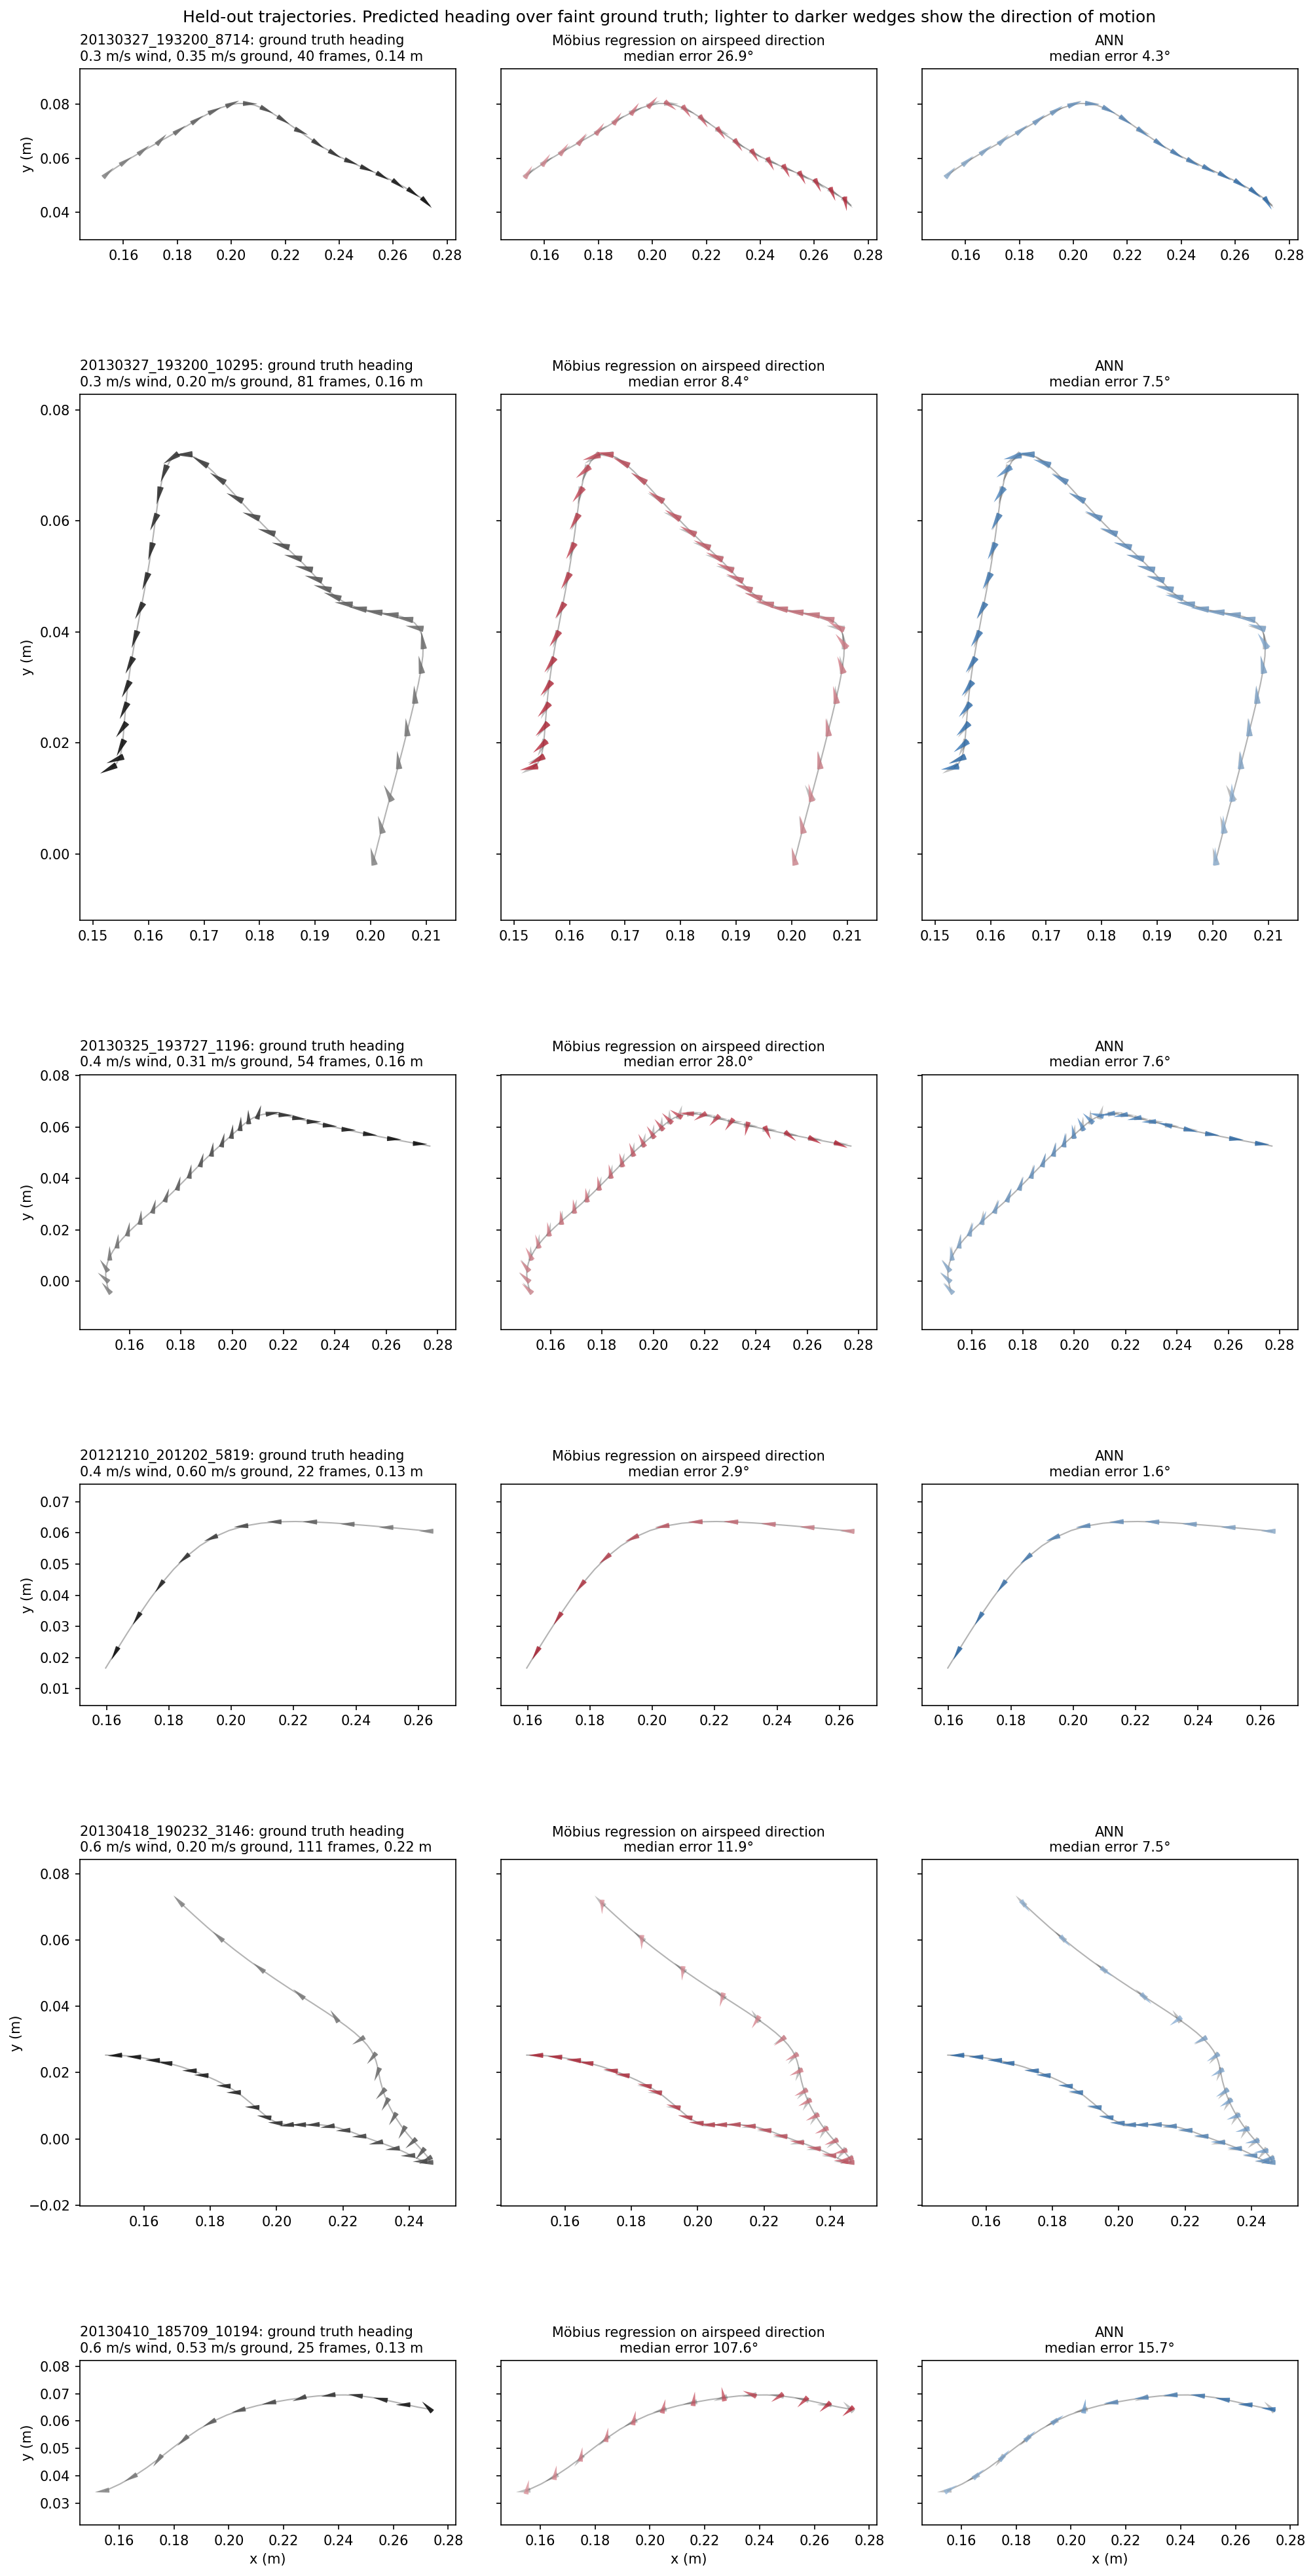

In [7]:
SELECTED = [candidates[i - 1] for i in (1, 3, 11, 12, 14, 19)]   # candidate rows; replace with your own pick
print(cand_table.set_index('row').loc[[candidates.index(tid) + 1 for tid in SELECTED if tid in candidates]].round(2).to_string())

fig = plot_examples(SELECTED)
fig.suptitle('Held-out trajectories. Predicted heading over faint ground truth; lighter to darker wedges show the direction of motion', y=1.0)
fig.savefig('../figures/ann_performance_examples.pdf', bbox_inches='tight')
fig.savefig('../figures/ann_performance_examples.png', dpi=300, bbox_inches='tight')
plt.show()